
# NYC Taxi Trip Records from JAN 2023 to JUN 2023

**Practical exercise**

*Author*

|Last name|Name|
|---|---|
|Borja Polanco|Daniela|

## Table of content

1. [Introduction](#introduction)
2. [Dataset Description](#dataset)
3. [Exploratory analysis (EDA) and Data Preprocessing](#eda)
4. [Data Visualization](#visualization)
5. [Machine Learning Model](#machine)
6. [Results/Findings](#results)
7. [Conclusion and Recommendations](#conclusion)

<a id="introduction"></a>

### 1. Introduction

Welcome to the introduction section.

<a id="dataset"></a>

### 2. Dataset Description

#### Importing modules

In [1]:
import os
import requests # To read url
import datetime as dt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
from IPython.display import display, Markdown

import warnings
warnings.filterwarnings("ignore")

#### Loading the dataset

In [2]:
df=pd.read_csv('nyc_yellow_taxi_trip_records_from_Jan_to_Aug_2023.csv')
df=df.copy()

df.head(10)

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,...,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,airport_fee
0,0,2,2023-06-30 23:59:59,2023-07-01 00:47:49,2.0,17.62,2.0,N,132,230,...,70.0,0.0,0.5,0.00,6.55,1.0,82.30,2.5,1.75,NaN
1,1,2,2023-06-30 23:59:57,2023-07-01 00:17:36,1.0,3.32,1.0,N,255,198,...,18.4,1.0,0.5,2.50,0.00,1.0,23.40,0.0,0.00,NaN
2,2,1,2023-06-30 23:59:55,2023-07-01 00:14:20,1.0,2.80,1.0,N,231,107,...,14.9,3.5,0.5,3.95,0.00,1.0,23.85,2.5,0.00,NaN
3,3,2,2023-06-30 23:59:55,2023-07-01 00:05:52,1.0,0.89,1.0,N,237,163,...,7.2,1.0,0.5,2.00,0.00,1.0,14.20,2.5,0.00,NaN
4,4,2,2023-06-30 23:59:55,2023-07-01 00:07:08,4.0,1.56,1.0,N,211,90,...,10.0,1.0,0.5,3.00,0.00,1.0,18.00,2.5,0.00,NaN
5,5,2,2023-06-30 23:59:54,2023-07-01 00:14:58,1.0,3.85,1.0,N,161,166,...,19.1,1.0,0.5,10.00,0.00,1.0,34.10,2.5,0.00,NaN
6,6,2,2023-06-30 23:59:53,2023-07-01 00:05:52,2.0,1.05,1.0,N,65,33,...,7.9,1.0,0.5,2.08,0.00,1.0,12.48,0.0,0.00,NaN
7,7,2,2023-06-30 23:59:53,2023-07-01 00:08:36,1.0,1.50,1.0,N,107,249,...,10.7,1.0,0.5,3.14,0.00,1.0,18.84,2.5,0.00,NaN
8,8,1,2023-06-30 23:59:52,2023-07-01 00:15:15,3.0,2.80,1.0,N,48,79,...,14.9,3.5,0.5,4.00,0.00,1.0,23.90,2.5,0.00,NaN
9,9,2,2023-06-30 23:59:51,2023-07-01 00:08:49,1.0,2.17,1.0,N,90,48,...,12.1,1.0,0.5,0.00,0.00,1.0,17.10,2.5,0.00,NaN


#### Information about the dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19493059 entries, 0 to 19493058
Data columns (total 21 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Unnamed: 0             int64  
 1   VendorID               int64  
 2   tpep_pickup_datetime   object 
 3   tpep_dropoff_datetime  object 
 4   passenger_count        float64
 5   trip_distance          float64
 6   RatecodeID             float64
 7   store_and_fwd_flag     object 
 8   PULocationID           int64  
 9   DOLocationID           int64  
 10  payment_type           int64  
 11  fare_amount            float64
 12  extra                  float64
 13  mta_tax                float64
 14  tip_amount             float64
 15  tolls_amount           float64
 16  improvement_surcharge  float64
 17  total_amount           float64
 18  congestion_surcharge   float64
 19  Airport_fee            float64
 20  airport_fee            float64
dtypes: float64(13), int64(5), object(3)
memory usage: 3.

The dataset provides information about trips taken by taxis in New York from January 2023 to June 2023. The website of [NYC Taxi & Limousine Commision](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) was consulted to find more information about the columns of the dataset

First look at the dataset:

- The dataset has a total of **21 columns and 19'493.059 entries**. Most of the columns are numerical columns where only 3 are non-numerical.

- The **column: Unnamed: 0** seems to represent the ID of each entry.

- The **column: VendorID** provides a code indicating the TPEP provider that provided the record.
    - 1 = Creative Mobile Technologies, LLC
    - 2 = Curb Mobility, LLC
    - 6 = Myle Technologies Inc
    - 7 = Helix

- The columns **tpep_pickup_datetime** and **tpep_dropoff_datetime** provide the date and time when the meter was respectively **engaged and disengaged**. This can be used to calculate trip duration.

- The **column passenger_count** gives the number of passengers in the vehicle. It has a Dtype as float64. It may be useful to convert it to a data type as int64. Normally, this kind of information is represented by round numbers - usually is 1,2 or 3 passengers, not 3.2 or 4.5 passengers

- The **column trip_distance** provides the elapsed trip distance **in miles** reported by the taximeter.

- The **column RatecodeID** is the final rate code in effect at the end of the trip. It can be useful to identify if there is going to be additional fees to the fare amount (Example: People going to the Airport pay an additional fee)
    - 1 = Standard rate
    - 2 = JFK
    - 3 = Newark
    - 4 = Nassau or Westchester
    - 5 = Negotiated fare
    - 6 = Group ride
    - 99 = Null/unknown
    
- The **column store_and_fwd_flag** indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.
    - Y = store and forward trip
    - N = not a store and forward trip
    
- The columns **PULocationID** and **DOLocationID** provide TLC Taxi Zone in which the taximeter was respectively **engaged and disengaged**. It may give insights of what are the most common zones in which trip starts and ends but external information may be required.

- The **column payment_type** is a numeric code signifying how the passenger paid for the trip.
    - 0 = Flex Fare trip
    - 1 = Credit card
    - 2 = Cash
    - 3 = No charge
    - 4 = Dispute
    - 5 = Unknown
    - 6 = Voided trip
    
- The **column fare_amount** is the time-and-distance fare calculated by the meter.

- The **column extra** provides miscellaneous extras and surcharges.

- The **column mta_tax** is the tax that is automatically triggered based on the metered rate in use.

- The **column tip_amount** is the tip amount – this field is automatically populated for credit card tips. Cash tips are not included. This can be quite an unpredictable variable due to many different factors influence tipping, and these factors often interact in complex ways(bill size, service quality, customer income, time, crowdedness and and so on).

- The **column tolls_amount** is the total amount of all tolls paid in trip.

- The **column improvement_surcharge** is the improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015.

- The **column total_amount** is the total amount charged to passengers. Does not include cash tips.

- The **column congestion_surcharge** is the total amount collected in trip for NYS congestion surcharge.

- The **column airport_fee** is for pick up only at LaGuardia and John F. Kennedy Airports

After a first glance at the main dataset, the **columns fare_amount and total_amount** are good candidates to be the target variables. In a large city like New York, many people depend on taxis for daily transportation, making it important to understand what influences taxi fare prices. This study focuses on key factors such as **trip distance, trip duration, additional taxes, and so on**, which are likely to impact the base and final fare.

Additionally, external data like **gas prices**—available from [The New York State Energy Research and Development Authority](https://www.nyserda.ny.gov/Energy-Prices/Motor-Gasoline/Weekly-Average-Motor-Gasoline-Prices)—can provide more context, especially regarding operational costs for drivers. The goal is to identify the main variables that affect taxi fares, offering insights that can benefit both passengers and taxi companies.

<a id="eda"></a>

### 3. Data Preprocessing

In [4]:
# Deleting columns not necessary for the analysis

col_to_delete=['Unnamed: 0',
 'VendorID',
 'store_and_fwd_flag'
]

The column Unnamed: 0 indicates only the ID of the entries. This will not significantly affect the fare amount and therefore could be deleted.
The column store_and_fwd_flag indicates if the trip record was held in vehicle memory before sending to the vendor but this does not provide useful information for the calculation of the fare amount.

In [5]:
df_process=df.drop(columns=col_to_delete)

Look at the missing values and correction measures will be made before adjusting any data types

In [6]:
columns=df_process.columns.to_list()

number_missing_values=[]
percentage_missing_values=[]
for col in columns:
    number_missing_values.append(df_process[col].isna().sum())
    percentage_missing_values.append(round(df_process[col].isna().sum()*100/len(df_process),2))

missing_values={'Column':columns,'Number of missing values':number_missing_values,'Percentage(%)':percentage_missing_values}
df_missing_values=pd.DataFrame.from_dict(missing_values)
df_missing_values

,Column,Number of missing values,Percentage(%)
0,tpep_pickup_datetime,0,0.00
1,tpep_dropoff_datetime,0,0.00
2,passenger_count,528530,2.71
3,trip_distance,0,0.00
4,RatecodeID,528530,2.71
5,PULocationID,0,0.00
6,DOLocationID,0,0.00
7,payment_type,0,0.00
8,fare_amount,0,0.00
9,extra,0,0.00


In [7]:
# Unique values of passenger count

for col in ['passenger_count','RatecodeID','congestion_surcharge','Airport_fee','airport_fee']:
    print(f"The unique values of {col} are:\n{df_process[col].unique()}\n")

The unique values of passenger_count are:
[ 2.  1.  4.  3. nan  5.  6.  0.  8.  9.  7.]

The unique values of RatecodeID are:
[ 2.  1. nan  4.  5.  3. 99.  6.]

The unique values of congestion_surcharge are:
[ 2.5   0.     nan -2.5   0.75  1.    2.75]

The unique values of Airport_fee are:
[ 1.75  0.     nan -1.75  1.25 -1.25]

The unique values of airport_fee are:
[  nan  0.    1.25 -1.25]



In [8]:
# Filling missing values for RatecodeID and passenger_count

df_process['RatecodeID'] = df_process['RatecodeID'].fillna(df_process['RatecodeID'].median())

df_process['passenger_count'] = df_process['passenger_count'].fillna(df_process['passenger_count'].median())

Before filling the missing values of the rest of the columns, it is necessary to handle the negative values encountered

In [9]:
print(f"The number of negative values for the column airport_fee is {len(df[df_process['airport_fee']<0])} which represents {round(len(df[df_process['airport_fee']<0])*100/len(df_process),2)}% of the total data")
print(f"The number of negative values for the column Airport_fee is {len(df[df_process['Airport_fee']<0])} which represents {round(len(df[df_process['Airport_fee']<0])*100/len(df_process),2)}% of the total data")
print(f"The number of negative values for the column congestion_surcharge is {len(df[df_process['congestion_surcharge']<0])} which represents {round(len(df[df_process['congestion_surcharge']<0])*100/len(df_process),2)}% of the total data")

The number of negative values for the column airport_fee is 3607 which represents 0.02% of the total data
The number of negative values for the column Airport_fee is 17788 which represents 0.09% of the total data
The number of negative values for the column congestion_surcharge is 137030 which represents 0.7% of the total data


The negative values of the columns a,b and c are not a representative part of the dataset so they can be discarded and then the missing values can be filled with the median. 

In [10]:
# Keeping positive and null values
df_process = df_process[(df_process['airport_fee'] >= 0) | (df_process['airport_fee'].isna())]
df_process = df_process[(df_process['Airport_fee'] >= 0) | (df_process['Airport_fee'].isna())]
df_process = df_process[(df_process['congestion_surcharge'] >= 0) | (df_process['congestion_surcharge'].isna())]

In [11]:
print(f"{df.shape[0]-df_process.shape[0]} were deleted from the dataset. New size {df_process.shape}")

152962 were deleted from the dataset. New size (19340097, 18)


In [12]:
# Filling missing values for congestion_surcharge

df_process['congestion_surcharge'] = df_process['congestion_surcharge'].fillna(df_process['congestion_surcharge'].median())

A new column Airport_fees is going to be created and it will be the combination of the columns of Airport_fee and airport_fee. 

The goal is to:

- If 'Airport_fee' is not null, it takes that value.

- If 'Airport_fee' is null, it takes the value from 'airport_fee'.

- If both are null, the result is null.

If after the combination, there are still null values, these will b replaced with the median.

In [13]:
df_process['Airport_fees'] = df_process['Airport_fee'].combine_first(df_process['airport_fee'])
df_process['Airport_fees'] = df_process['Airport_fees'].fillna(df_process['Airport_fees'].median())

# Deleting columns Airport_fee and airport_fee

col_to_delete=['Airport_fee',
 'airport_fee'
]

df_process=df_process.drop(columns=col_to_delete)

In [14]:
# Adjusting data types of the dates

df_process['tpep_pickup_datetime'] = pd.to_datetime(df_process['tpep_pickup_datetime'])
df_process['tpep_dropoff_datetime'] = pd.to_datetime(df_process['tpep_dropoff_datetime'])

# Creatin column for the duration of the trip

df_process['trip_duration']=df_process['tpep_dropoff_datetime']-df_process['tpep_pickup_datetime']
df_process['trip_duration']=df_process['trip_duration'].dt.total_seconds()/60 # to convert the information to minutes

# Change column passenger_count and RatecodeID's values to integers
df_process = df_process.astype({'passenger_count': 'int64', 'RatecodeID': 'int64'})

In [15]:
# Checking for duplicated values
print(f"The number of duplicated values is: {df_process.duplicated().sum()}\nThis represents {round(df_process.duplicated().sum()*100/len(df_process))}%")

The number of duplicated values is: 0
This represents 0%


In [16]:
df_process.describe().T

,count,mean,min,25%,50%,75%,max,std
tpep_pickup_datetime,19340097,2023-04-03 12:14:50.722819072,2023-01-01 00:00:00,2023-02-18 01:06:03,2023-04-04 14:34:13,2023-05-17 17:57:38,2023-06-30 23:59:59,NaN
tpep_dropoff_datetime,19340097,2023-04-03 12:31:51.246514688,2023-01-01 00:03:28,2023-02-18 01:19:55,2023-04-04 14:51:21,2023-05-17 18:19:10,2023-07-03 16:31:24,NaN
passenger_count,19340097.0,1.353128,0.0,1.0,1.0,1.0,9.0,0.882891
trip_distance,19340097.0,4.087264,0.0,1.08,1.8,3.42,342344.85,250.594352
RatecodeID,19340097.0,1.551726,1.0,1.0,1.0,1.0,99.0,6.86247
PULocationID,19340097.0,165.633622,1.0,132.0,162.0,234.0,265.0,64.066123
DOLocationID,19340097.0,164.210087,1.0,114.0,162.0,234.0,265.0,69.916733
payment_type,19340097.0,1.171643,0.0,1.0,1.0,1.0,5.0,0.498375
fare_amount,19340097.0,19.463085,-900.0,9.3,13.5,21.2,386983.63,89.851447
extra,19340097.0,1.611423,-7.5,0.0,1.0,2.5,96.38,1.825326


The variables trip_distance, fare_amount, extra, mta_tax, tip_amount,tolls_amount, improvement_surcharge, total_amount, trip_duration have negative values. These observations are not reasonable values for these variables and therefore will be removed (a negative fare amount does not make much sense)

In [17]:
# Keeping only observations having reasonable values 

df_process = df_process[(df_process.fare_amount>0)]
df_process = df_process[(df_process.total_amount>0)]
df_process = df_process[(df_process.trip_distance>0)]
df_process = df_process[(df_process.trip_duration>0)]
df_process = df_process[(df_process.tip_amount>=0)]
df_process = df_process[(df_process.mta_tax>=0)]

In [18]:
df_process.describe().T

,count,mean,min,25%,50%,75%,max,std
tpep_pickup_datetime,19065313,2023-04-03 12:32:40.008354816,2023-01-01 00:00:00,2023-02-18 01:34:44,2023-04-04 15:10:00,2023-05-17 17:45:30,2023-06-30 23:59:59,NaN
tpep_dropoff_datetime,19065313,2023-04-03 12:49:45.430637568,2023-01-01 00:04:16,2023-02-18 01:48:20,2023-04-04 15:28:09,2023-05-17 18:07:35,2023-07-01 23:14:14,NaN
passenger_count,19065313.0,1.354848,0.0,1.0,1.0,1.0,9.0,0.884569
trip_distance,19065313.0,4.119321,0.01,1.1,1.83,3.48,335004.33,239.369074
RatecodeID,19065313.0,1.477211,1.0,1.0,1.0,1.0,99.0,6.399215
PULocationID,19065313.0,165.709089,1.0,132.0,162.0,234.0,265.0,63.951645
DOLocationID,19065313.0,164.233346,1.0,114.0,162.0,234.0,265.0,69.863019
payment_type,19065313.0,1.166134,0.0,1.0,1.0,1.0,4.0,0.482427
fare_amount,19065313.0,19.396792,0.01,9.3,13.5,21.2,386983.63,90.374643
extra,19065313.0,1.625822,0.0,0.0,1.0,2.5,96.38,1.825431


The data from the website [NYSERDA](https://www.nyserda.ny.gov/Energy-Prices/Motor-Gasoline/Weekly-Average-Motor-Gasoline-Prices) is merged with the dataset to integrate the gas prices.

**Adding external data for the analysis - Gas prices**

In [19]:
from selenium import webdriver

# Getting the gas prices tables from the NYSERDA
driver = webdriver.Chrome()
driver.get("https://www.nyserda.ny.gov/Energy-Prices/Motor-Gasoline/Weekly-Average-Motor-Gasoline-Prices")

html = driver.page_source
gas_prices = pd.read_html(html)
print(len(gas_prices))
driver.quit()

5


In [20]:
gas_prices[0]

,Region,Price (cents per gallon):
0,New York Statewide,310.3
1,Upstate New York,319.8
2,Downstate New York,300.2
3,New York City Metropolitan Area,303.5


In [21]:
gas_prices[1]

Current Year                                           Last Year          
           Date: Price (cents per gallon): Price (cents per gallon): % Change:
0     09/29/2025                     310.3                     312.6      -0.7
1     09/22/2025                     312.6                     318.8      -1.9
2     09/15/2025                     316.1                     322.9      -2.1
3     09/08/2025                     315.6                     327.6      -3.7
4     09/01/2025                     309.8                     334.6      -7.4
..           ...                       ...                       ...       ...
138   01/30/2023                     347.7                     347.0       0.2
139   01/23/2023                     342.2                     341.6       0.2
140   01/16/2023                     332.7                     339.3      -1.9
141   01/09/2023                     331.7                     339.8      -2.4
142   01/02/2023                     330.1                     341.9      -3.5

[143 rows x 4 columns]

In [22]:
NY_Dates_GasPrices = gas_prices[1].copy()
NY_Dates_GasPrices.iloc[:,0] = pd.to_datetime(NY_Dates_GasPrices.iloc[:,0])
NY_Dates_GasPrices = NY_Dates_GasPrices.iloc[:,[0,1]]   # keep Date + NY Avg Price
NY_Dates_GasPrices.columns = ["Date", "Price"]
NY_Dates_GasPrices["Date"] = pd.to_datetime(NY_Dates_GasPrices["Date"])

In [23]:
NY_Dates_GasPrices

,Date,Price
0,2025-09-29,310.3
1,2025-09-22,312.6
2,2025-09-15,316.1
3,2025-09-08,315.6
4,2025-09-01,309.8
...,...,...
138,2023-01-30,347.7
139,2023-01-23,342.2
140,2023-01-16,332.7
141,2023-01-09,331.7


NY gas prices are showing the weekly average instead of daily prices. The idea is to create a separate dataframe based on days instead of weeks and then merge these records with NY_Dates_GasPrices.

In [24]:
all_dates = pd.DataFrame({
    "Date": pd.date_range(
        start=NY_Dates_GasPrices["Date"].min(),
        end=NY_Dates_GasPrices["Date"].max(),
        freq="D"
    )
})

dates_Merged = all_dates.merge(NY_Dates_GasPrices, on="Date", how="left")

# Handling null values in the new dataframe
dates_Merged["Price"].fillna(method="ffill", inplace=True) # replaces the NULL values with the value from the previous row
dates_Merged["Price"].fillna(method="bfill", inplace=True) # replaces each missing value with the next valid observation encountered

# Count duplicate days
dup_count = dates_Merged["Date"].duplicated().sum()
print("Duplicate dates:", dup_count)

# If >0, show them
if dup_count > 0:
    print(dates_Merged[dates_Merged["Date"].duplicated(keep=False)])

Duplicate dates: 0


Merging df_process (taxi trip records) and dates_Merged to match and extract corresponding gasoline prices based on pickup dates. 

In [25]:
df_process["Date"] = df_process["tpep_pickup_datetime"].dt.date
dates_Merged["Date"] = dates_Merged["Date"].dt.date

df_process = df_process.merge(dates_Merged, on="Date", how="left")
df_process.rename(columns={"Price": "Gas_Prices"}, inplace=True)
df_process.drop(columns=["Date"], inplace=True)

# Filling null values with the median
df_process['Gas_Prices'] = df_process['Gas_Prices'].fillna(df_process['Gas_Prices'].median())

In [26]:
df_process.head()

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fees,trip_duration,Gas_Prices
0,2023-06-30 23:59:59,2023-07-01 00:47:49,2,17.62,2,132,230,1,70.0,0.0,0.5,0.00,6.55,1.0,82.30,2.5,1.75,47.833333,359.2
1,2023-06-30 23:59:57,2023-07-01 00:17:36,1,3.32,1,255,198,1,18.4,1.0,0.5,2.50,0.00,1.0,23.40,0.0,0.00,17.650000,359.2
2,2023-06-30 23:59:55,2023-07-01 00:14:20,1,2.80,1,231,107,1,14.9,3.5,0.5,3.95,0.00,1.0,23.85,2.5,0.00,14.416667,359.2
3,2023-06-30 23:59:55,2023-07-01 00:05:52,1,0.89,1,237,163,1,7.2,1.0,0.5,2.00,0.00,1.0,14.20,2.5,0.00,5.950000,359.2
4,2023-06-30 23:59:55,2023-07-01 00:07:08,4,1.56,1,211,90,1,10.0,1.0,0.5,3.00,0.00,1.0,18.00,2.5,0.00,7.216667,359.2


In [27]:
df_process.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19065313 entries, 0 to 19065312
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[ns]
 1   tpep_dropoff_datetime  datetime64[ns]
 2   passenger_count        int64         
 3   trip_distance          float64       
 4   RatecodeID             int64         
 5   PULocationID           int64         
 6   DOLocationID           int64         
 7   payment_type           int64         
 8   fare_amount            float64       
 9   extra                  float64       
 10  mta_tax                float64       
 11  tip_amount             float64       
 12  tolls_amount           float64       
 13  improvement_surcharge  float64       
 14  total_amount           float64       
 15  congestion_surcharge   float64       
 16  Airport_fees           float64       
 17  trip_duration          float64       
 18  Gas_Prices          

The columns 'RatecodeID' and 'payment_type' have numerical values, but they are nominal numbers - used as labels to identify or categorize something without implying quantity or order. They're just **labels**, not meaningful numbers

Using them directly (as integers) could mislead most machine learning algorithms into thinking there's a numeric relationship between the values. The model might incorrectly assume that "3" has more influence than "1", just because of its numeric value

Therefore, these categorical variables are going to be converted into dummy/indicator variables (binary values) to give directionality to the variable, allowing the regression to compare two categories instead of expecting a continuous increase

In [28]:
# One-Hot Encode 'origin'
df_process = pd.get_dummies(df_process, columns=['RatecodeID'], prefix='RatecodeID',dtype=int,drop_first=False)
df_process = pd.get_dummies(df_process, columns=['payment_type'], prefix='payment_type',dtype=int,drop_first=False)

In [29]:
df_process.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19065313 entries, 0 to 19065312
Data columns (total 29 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[ns]
 1   tpep_dropoff_datetime  datetime64[ns]
 2   passenger_count        int64         
 3   trip_distance          float64       
 4   PULocationID           int64         
 5   DOLocationID           int64         
 6   fare_amount            float64       
 7   extra                  float64       
 8   mta_tax                float64       
 9   tip_amount             float64       
 10  tolls_amount           float64       
 11  improvement_surcharge  float64       
 12  total_amount           float64       
 13  congestion_surcharge   float64       
 14  Airport_fees           float64       
 15  trip_duration          float64       
 16  Gas_Prices             float64       
 17  RatecodeID_1           int64         
 18  RatecodeID_2        

The variables are going to be divided into numerical variables and categorical variables for a better visualization of the data.

In [30]:
# Numerical variables

features_num = ['passenger_count','trip_distance','fare_amount','total_amount',
                'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
                'congestion_surcharge','Airport_fees','trip_duration','Gas_Prices']

# Categorical variables

features_cat = ['PULocationID','DOLocationID','RatecodeID_1','RatecodeID_2','RatecodeID_3',
                'RatecodeID_4','RatecodeID_5','RatecodeID_6','RatecodeID_99','payment_type_0',
               'payment_type_1','payment_type_2','payment_type_3','payment_type_4']



<a id="visualization"></a>

### 4. Data Visualization

This is the visualization section.


**Visualization for numerical variables**

*Boxplots - Identifiying Outliers*

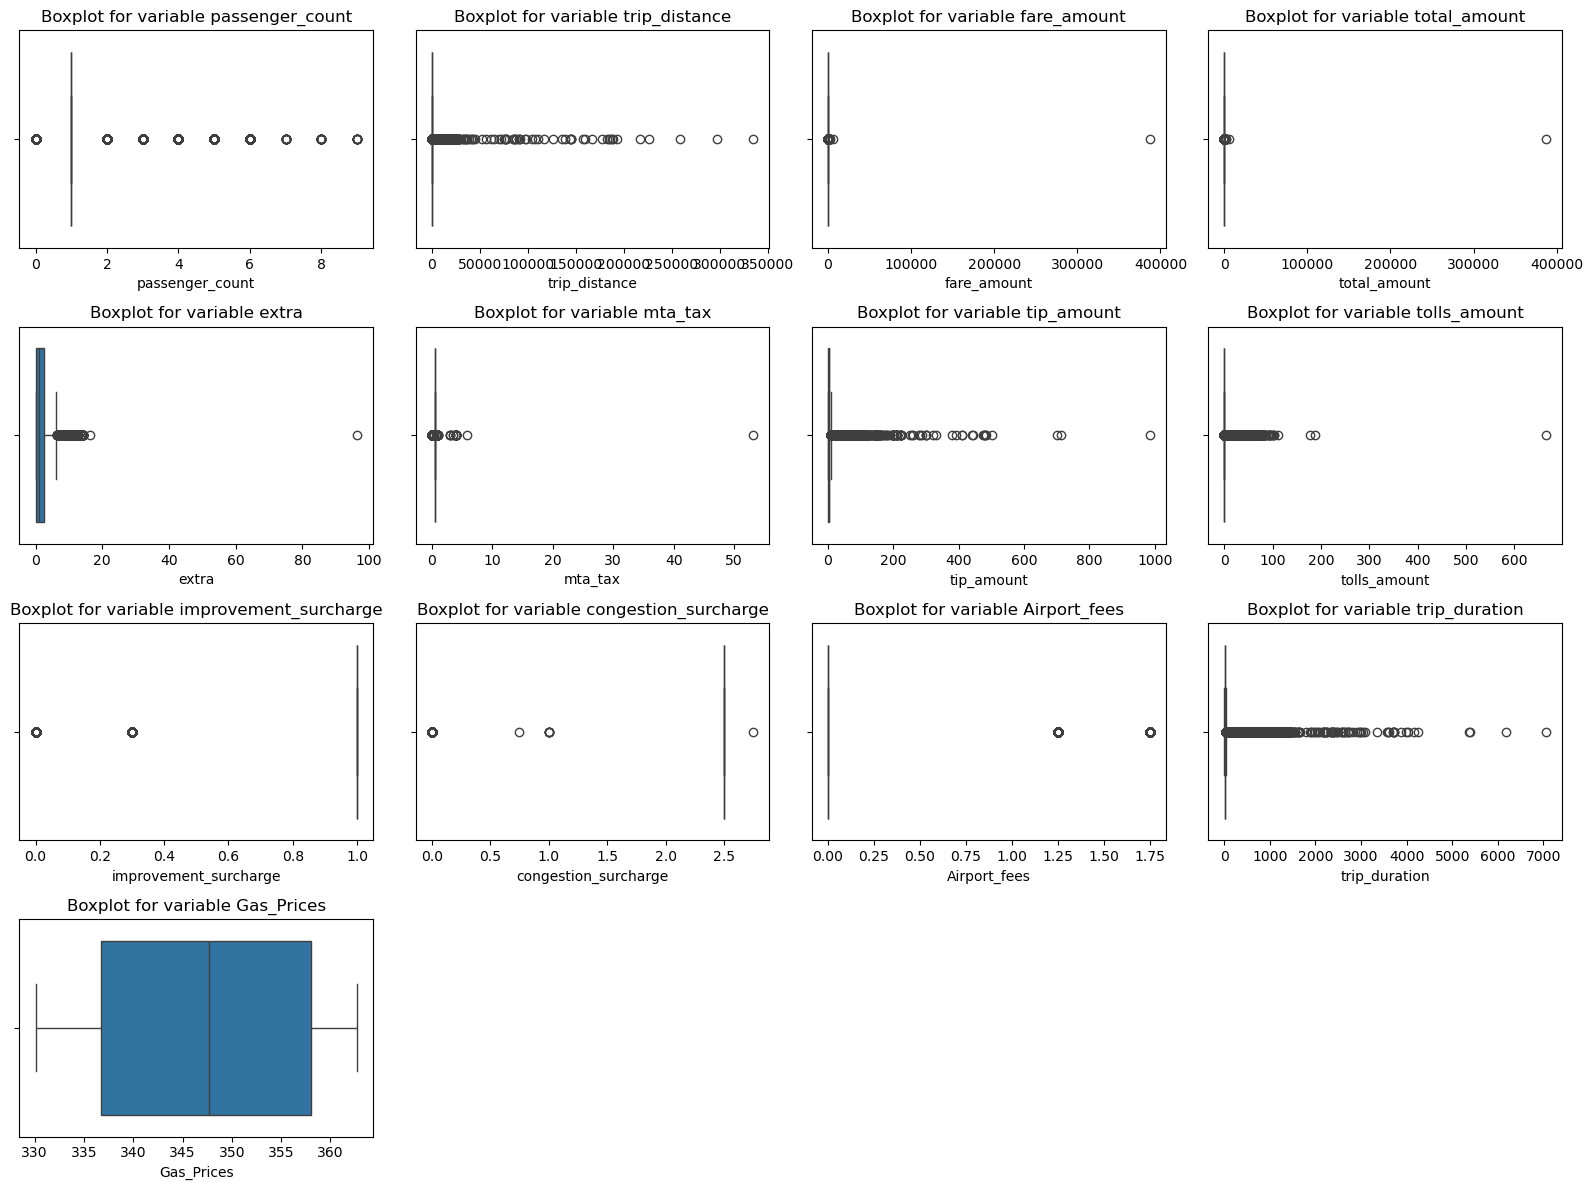

In [31]:
n = len(features_num)
ncols = 4
nrows = int(np.ceil(n / ncols))

# Create subplot
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.flatten() # Flatten to easily iterate 

# Plot each histogram
for i, col in enumerate(features_num):
    sns.boxplot(data=df_process,x=col, ax=axes[i])
    axes[i].set_title(f"Boxplot for variable {col}")

# hide remaining axes if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.savefig("scatter_fare_distance.png", dpi=300, bbox_inches="tight")
plt.show()




In [53]:

# Display the transposed describe table
display(df_process.describe().T)

df_process.describe().T.to_excel("table1.xlsx")

,count,mean,min,25%,50%,75%,max,std
tpep_pickup_datetime,19065313,2023-04-03 12:32:40.008354816,2023-01-01 00:00:00,2023-02-18 01:34:44,2023-04-04 15:10:00,2023-05-17 17:45:30,2023-06-30 23:59:59,NaN
tpep_dropoff_datetime,19065313,2023-04-03 12:49:45.430637568,2023-01-01 00:04:16,2023-02-18 01:48:20,2023-04-04 15:28:09,2023-05-17 18:07:35,2023-07-01 23:14:14,NaN
passenger_count,19065313.0,1.354848,0.0,1.0,1.0,1.0,9.0,0.884569
trip_distance,19065313.0,4.119321,0.01,1.1,1.83,3.48,335004.33,239.369074
PULocationID,19065313.0,165.709089,1.0,132.0,162.0,234.0,265.0,63.951645
DOLocationID,19065313.0,164.233346,1.0,114.0,162.0,234.0,265.0,69.863019
fare_amount,19065313.0,19.396792,0.01,9.3,13.5,21.2,386983.63,90.374643
extra,19065313.0,1.625822,0.0,0.0,1.0,2.5,96.38,1.825431
mta_tax,19065313.0,0.497186,0.0,0.5,0.5,0.5,53.16,0.039746
tip_amount,19065313.0,3.5405,0.0,1.0,2.86,4.4,984.3,3.956273


As shown in the summary above, we have outliers that can significantly affect the model’s performance.
This affects concretely the columns trip_distance,fare_amount,total_amount,trip_duration, extra,mta_tax,tip_amount and tolls_amount.
The IQR method is going to be used to identify outliers setting up a “fence” outside of Q1(25%) and Q3(75%). Any values that fall outside of this fence are considered outliers adn filter our of the dataset. -> (Q1-1.5IQR)<=Values<=(Q3+1.5IQR)

In [33]:
# Remove outliers using IQR method

def remove_outliers_iqr(df, cols):
    clean_df = df.copy()
    for col in cols:
        Q1 = clean_df[col].quantile(0.25)
        Q3 = clean_df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        clean_df = clean_df[(clean_df[col] >= lower) & (clean_df[col] <= upper)]
    return clean_df

col_outliers=['trip_distance','fare_amount','total_amount','trip_duration','extra','mta_tax','tip_amount','tolls_amount']
df_no_outliers = remove_outliers_iqr(df_process, col_outliers)

print("Original dataset shape:", df_process.shape)
print("After IQR outlier removal:", df_no_outliers.shape)

# Sample instead of the full dataset. Still see the patterns(for EDA), but without killing RAM. For the machine learning the whole dataset will be used
df_no_outliers_full = df_no_outliers.copy()
df_no_outliers = df_no_outliers.sample(n=min(100000, len(df)))

print(f"\nSize of the sample:", df_no_outliers.shape)
print(f"\nSize of the total population:", df_no_outliers_full.shape)

Original dataset shape: (19065313, 29)
After IQR outlier removal: (15490993, 29)

Size of the sample: (100000, 29)

Size of the total population: (15490993, 29)


*Histograms*

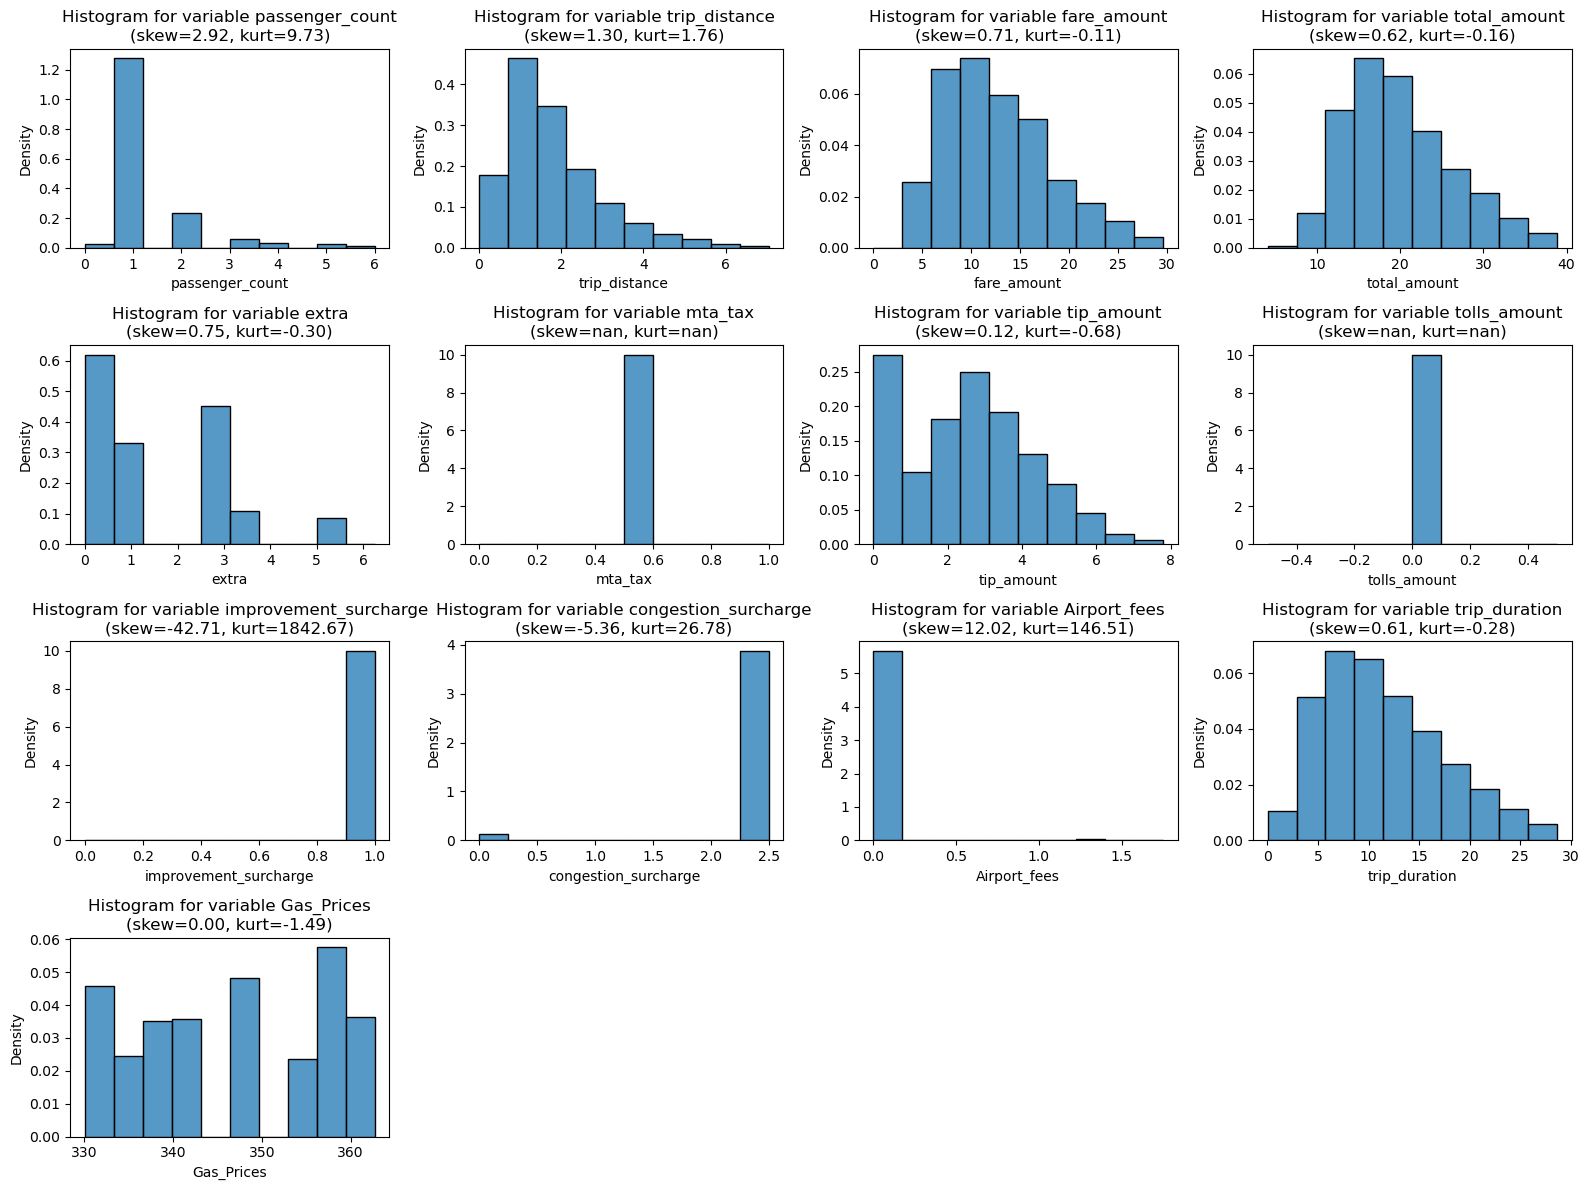

In [34]:
n = len(features_num)
ncols = 4
nrows = int(np.ceil(n / ncols))

# Create subplot
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.flatten() # Flatten to easily iterate 

# Plot each histogram
for i, col in enumerate(features_num):
    sns.histplot(data=df_no_outliers, x=col, ax=axes[i], kde=False,stat="density",bins=10)
    axes[i].set_title(f"Histogram for variable {col}\n(skew={skew(df_no_outliers[col]):.2f}, kurt={kurtosis(df_no_outliers[col]):.2f})")

# hide remaining axes if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.savefig("histogram.png", dpi=300, bbox_inches="tight")
plt.show()

|Feature|Comment|
|---|---|
|Passenger count|Mostly 1 passenger (sharp peak at 1)|
|Trip distance|Right-skewed (positively skewed). Most trips are short (0–2 miles)|
|Fare amount|Fairly symmetric with moderate spread. Not too skewed|
|Total amount|Similar to fair_amount|
|Extra, MTA tax, Improvement surcharge, Congestion surcharge, Airport fees|Strongly peaked at fixed amounts. Essentially categorical dummy-like charges|
|Tip amount|Right-skewed. Most tips are small (0–3)|
|Tolls amount|Almost all zero → sparse variable|
|Trip duration|Most trips are short (0-15 min), Right-skewed but not extreme|
|Gas Prices|Uniform distribution. Stable, no skew.|

**Visualization for categorical variables**

*Bar plot*

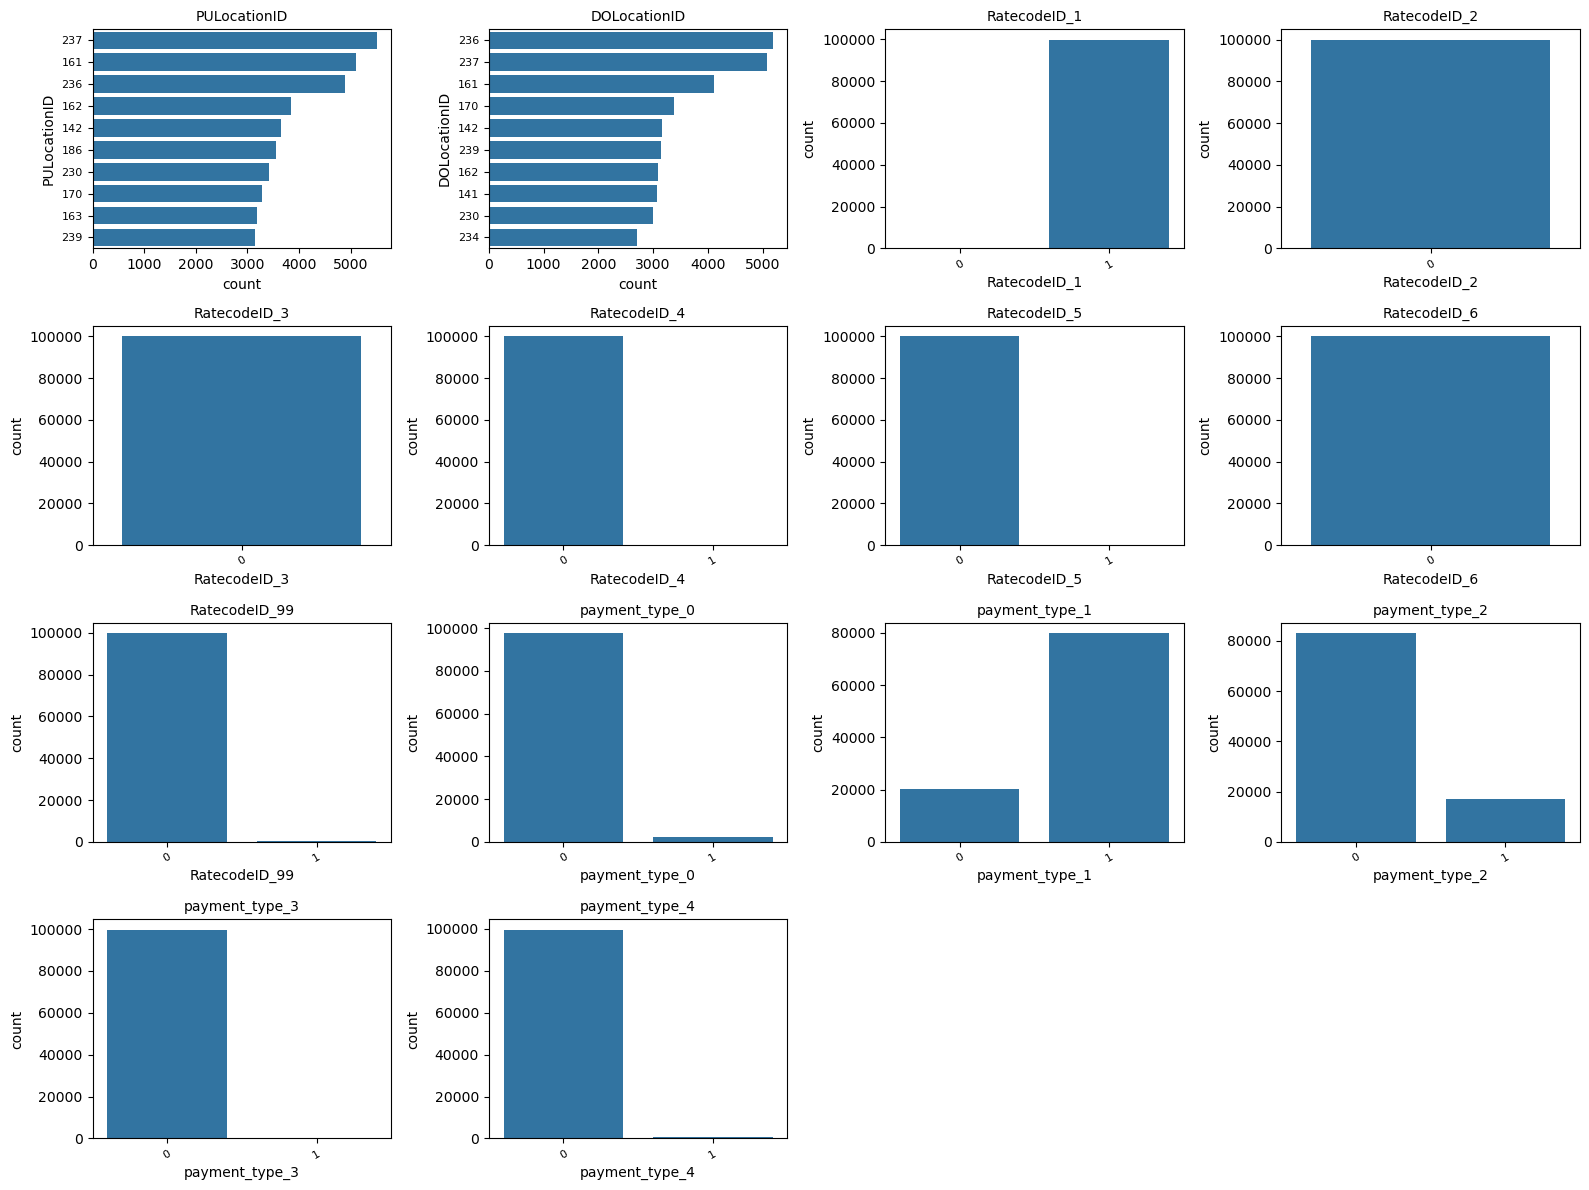

In [35]:
n = len(features_cat)
ncols = 4
nrows = int(np.ceil(n / ncols))

# Create subplot
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.flatten() # Flatten to easily iterate 

# Plot each histogram
for i, col in enumerate(features_cat):
    n_unique = df_no_outliers[col].nunique()

    if n_unique <= 10:  
        # Small number of categories → vertical barplot
        sns.countplot(data=df_no_outliers, x=col, ax=axes[i])
        axes[i].tick_params(axis='x', rotation=30, labelsize=8)

    else:  
        # Many categories → top 10, horizontal barplot
        top_k = df_no_outliers[col].value_counts().nlargest(10).index
        sns.countplot(data=df_no_outliers, y=col, ax=axes[i], order=top_k)
        axes[i].tick_params(axis='y', labelsize=8)

    axes[i].set_title(f"{col}", fontsize=10)

# Hide unused subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.savefig("barplot.png", dpi=300, bbox_inches="tight")
plt.show()

* Pickup and Dropoff Location IDs (PULocationID, DOLocationID)

    * Data is heavily concentrated around certain zones (probably airports, business hubs, downtown areas).
    
* RatecodeID

    * Most rides fall into RatecodeID = 1 (probably "standard rate").
    * A few others like 2, 3, 4, 5, 6 exist, but they’re extremely rare compared to standard.

* Payment Type

    * Payment_type_1 is the most common (likely credit card).
    * Payment_type_2 and 0 (maybe cash/unknown) have significant counts but much smaller.
    * Payment_type_3, 4 are extremely rare.
    * Clear skew → majority of customers use credit card, cash is secondary.

**Correlation heatmap**

In exploratory data analysis (EDA), we’re usually interested in strong linear relationships.
The dataset has a great number of columns, which could mislead the identification of the patterns and relationships.
Using a |corr| ≥ 0.3 threshold is practical because it highlights substantial relationships while filtering out weak/noise-level correlations, helping guide feature selection and interpretation.

A threshold of |0.3| is commonly used because it marks a moderate correlation:

* |r| < 0.3 → weak

* 0.3 ≤ |r| < 0.5 → moderate

* |r| ≥ 0.5 → strong

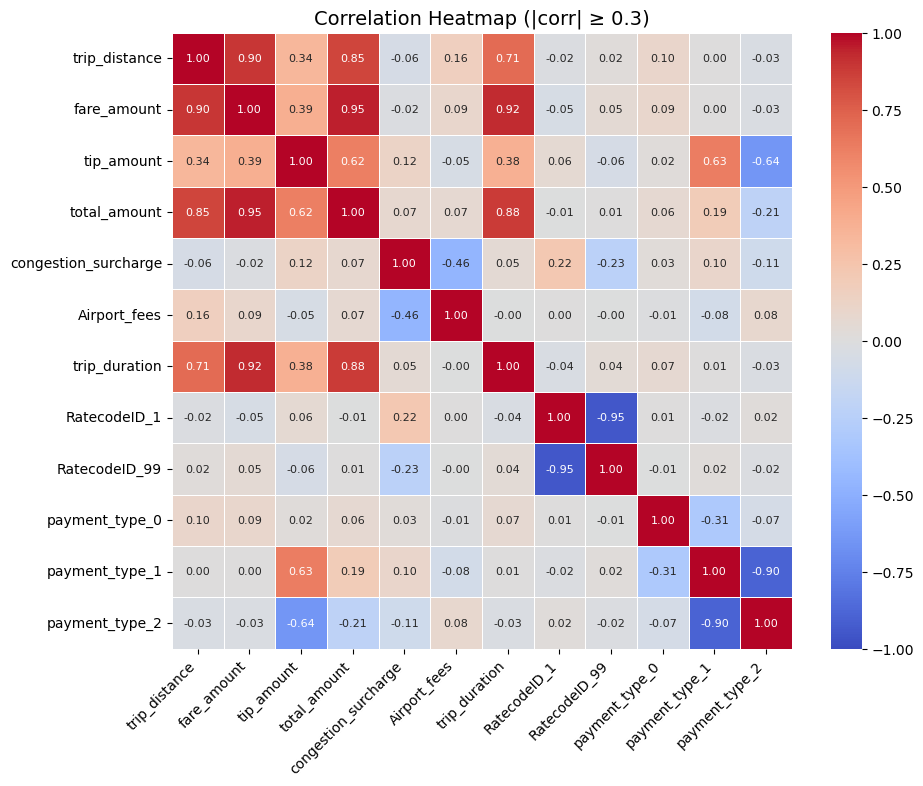

In [36]:
# Correlation matrix
corr = df_no_outliers.corr(numeric_only=True)

# Mask the diagonal so we ignore self-correlations
mask_diag = np.eye(len(corr), dtype=bool)

# Keep only variables that have correlation > 0.3 with *another* variable
strong_corr_vars = corr.columns[(corr.abs().where(~mask_diag) >= 0.3).any()]

# Subset correlation matrix
filtered_corr = corr.loc[strong_corr_vars, strong_corr_vars]

# Create mask for upper triangle (to avoid duplicate mirror)
mask = np.triu(np.ones_like(filtered_corr, dtype=bool))

# Plot heatmap
plt.figure(figsize=(10,8))
sns.heatmap(filtered_corr, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, cbar=True,
            linewidths=0.5, annot_kws={"size":8})
plt.title("Correlation Heatmap (|corr| ≥ 0.3)", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.savefig("correlationmatrix.png", dpi=300, bbox_inches="tight")
plt.show()

***Interpretation of the Heatmap***

1. Strong positive correlations

    * fare_amount, total_amount, trip_distance, and trip_duration are highly correlated (≥ 0.85) → Longer trips naturally cost more, take more time, and increase the final amount.

    * fare_amount ↔ total_amount (0.95) is expected since total amount = fare + tips + extras.

2. Moderate correlations

    * tip_amount has moderate correlation with total_amount (0.62) → Tips are a component of total, but not always proportional.
    * payment_type_1 correlates positively with tip_amount (0.63), and negatively with payment_type_2 (-0.90)→ People paying with a credit card (type 1) tend to leave tips, while cash payers (type 2) tend not to.

3. Negative correlations

    * payment_type_1 and payment_type_2 are strongly negatively correlated (-0.90) → Makes sense: they are mutually exclusive categories encoded as dummies.
    * RatecodeID_1 vs RatecodeID_99 also highly negatively correlated (-0.96) → Same reason: one-hot encoded features for mutually exclusive rate codes.

4. Low/no correlations

    * Rate codes in general show very weak relationships with trip or fare features → Suggests rate codes are independent categorical labels.

In [37]:
features_num = [
    'passenger_count','trip_distance','extra','mta_tax','tip_amount',
    'tolls_amount','improvement_surcharge','congestion_surcharge',
    'Airport_fees','trip_duration','Gas_Prices'
]

features_cat = [
    'PULocationID','DOLocationID',
    'RatecodeID_1','RatecodeID_2','RatecodeID_3','RatecodeID_4',
    'RatecodeID_5','RatecodeID_6','RatecodeID_99',
    'payment_type_0','payment_type_1','payment_type_2',
    'payment_type_3','payment_type_4'
]

all_features = features_num + features_cat
targets = ["fare_amount", "total_amount"]

**Impact of the features on fare_amount**

*Numerical features*

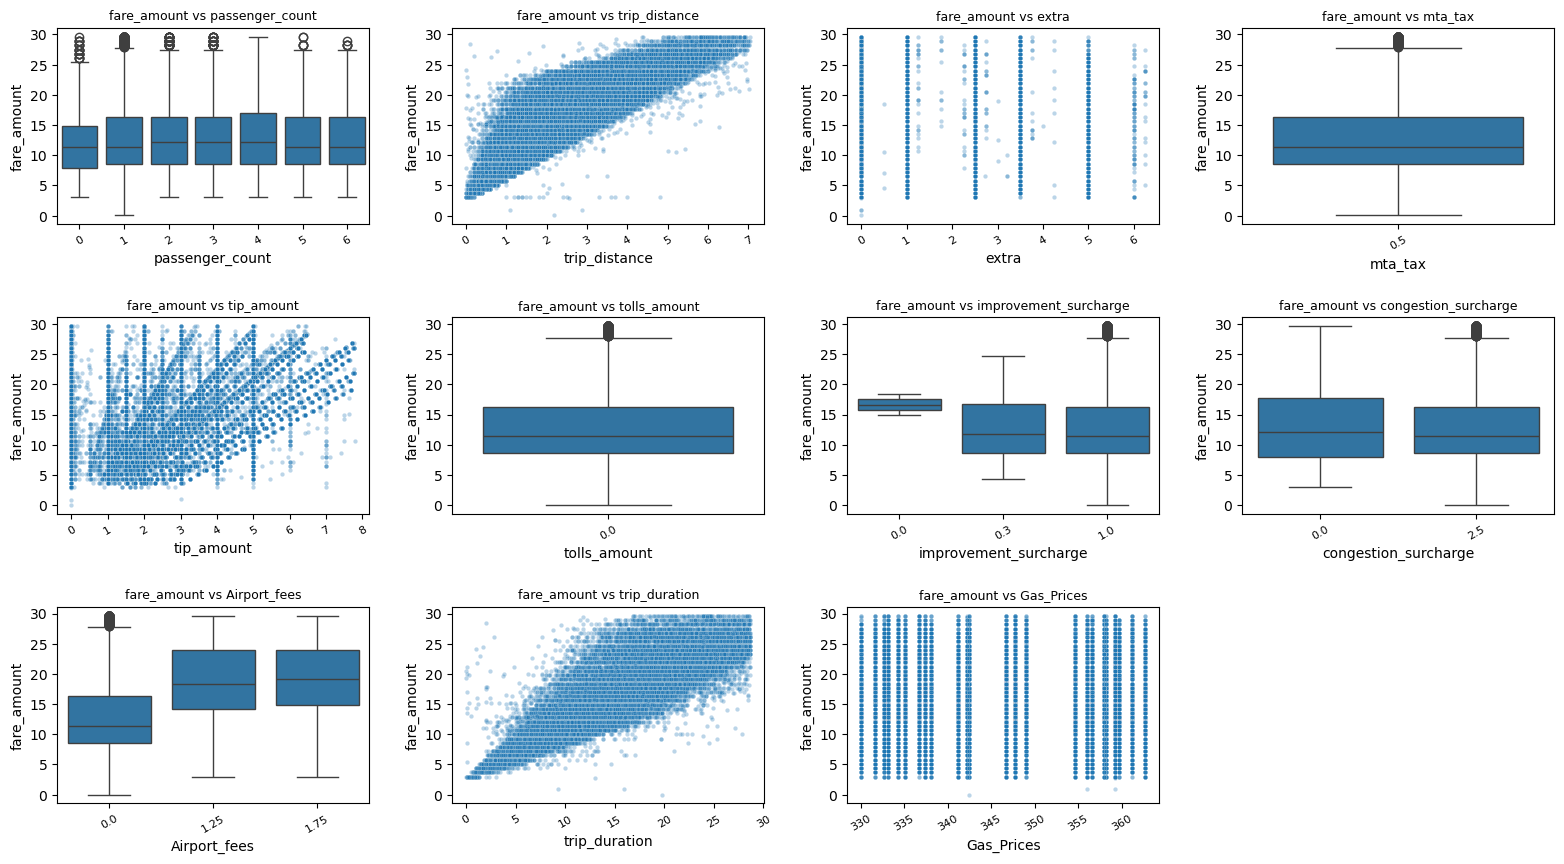

In [38]:
n = len(features_num)
ncols = 4
nrows = int(np.ceil(n / ncols))

# Create subplot
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.flatten() # Flatten to easily iterate 

numeric_target=targets[0]

# Plot each scatter plot
for i, col in enumerate(features_num):
    if df_no_outliers[col].nunique() < 10:
        sns.boxplot(data=df_no_outliers, x=col, y=numeric_target, ax=axes[i])
    else:
        sns.scatterplot(data=df_no_outliers, x=col, y=numeric_target, ax=axes[i], alpha=0.3, s=10)
    
    axes[i].set_title(f"{numeric_target} vs {col}", fontsize=9)
    axes[i].tick_params(axis='x', rotation=30, labelsize=8)

# Hide unused subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(pad=2.0)
plt.savefig("diagramsfornumericalvariables-fareamount.png", dpi=300, bbox_inches="tight")
plt.show()

*Categorical features*

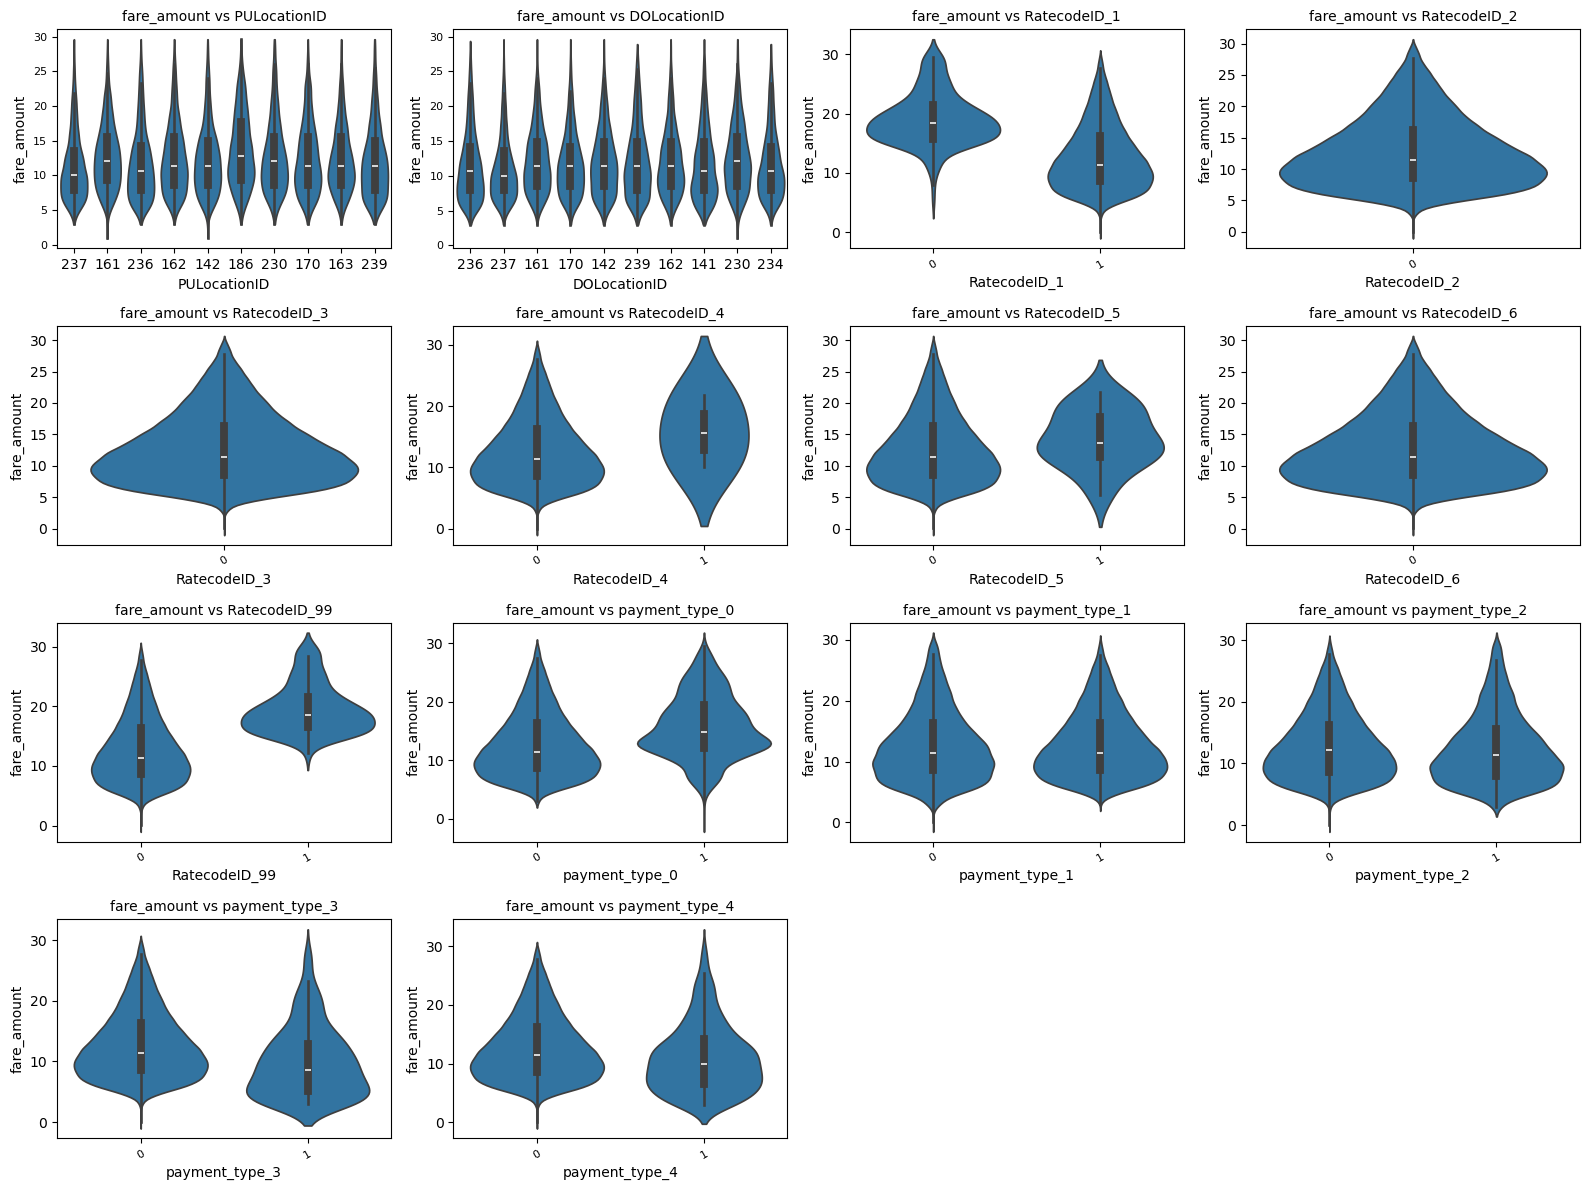

In [39]:
n = len(features_cat)
ncols = 4
nrows = int(np.ceil(n / ncols))

numeric_target=targets[0]

# Create subplot
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.flatten() # Flatten to easily iterate 


# Plot each histogram
for i, col in enumerate(features_cat):
    n_unique = df_no_outliers[col].nunique()

    if n_unique <= 10:  
        # Small number of categories → vertical barplot
        sns.violinplot(data=df_no_outliers, x=col, y=numeric_target,ax=axes[i])
        axes[i].tick_params(axis='x', rotation=30, labelsize=8)

    else:  
        # Select top 10 most frequent categories
        top_k = df_no_outliers[col].value_counts().nlargest(10).index
        
        # Filter dataset to only those categories
        subset = df_no_outliers[df_no_outliers[col].isin(top_k)]
        
        # Violinplot
        sns.violinplot(data=subset,x=col,y=numeric_target,
                       ax=axes[i],order=top_k,
                       scale="width",  # widths comparable
                       cut=0           # no extension beyond observed data
                      )
        axes[i].tick_params(axis='y', labelsize=8)

    axes[i].set_title(f"{numeric_target} vs {col}", fontsize=10)


# hide remaining axes if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.savefig("diagramsforcategoricalvariables-fareamount.png", dpi=300, bbox_inches="tight")
plt.show()

**Impact of the features on total_amount**

*Numerical features*

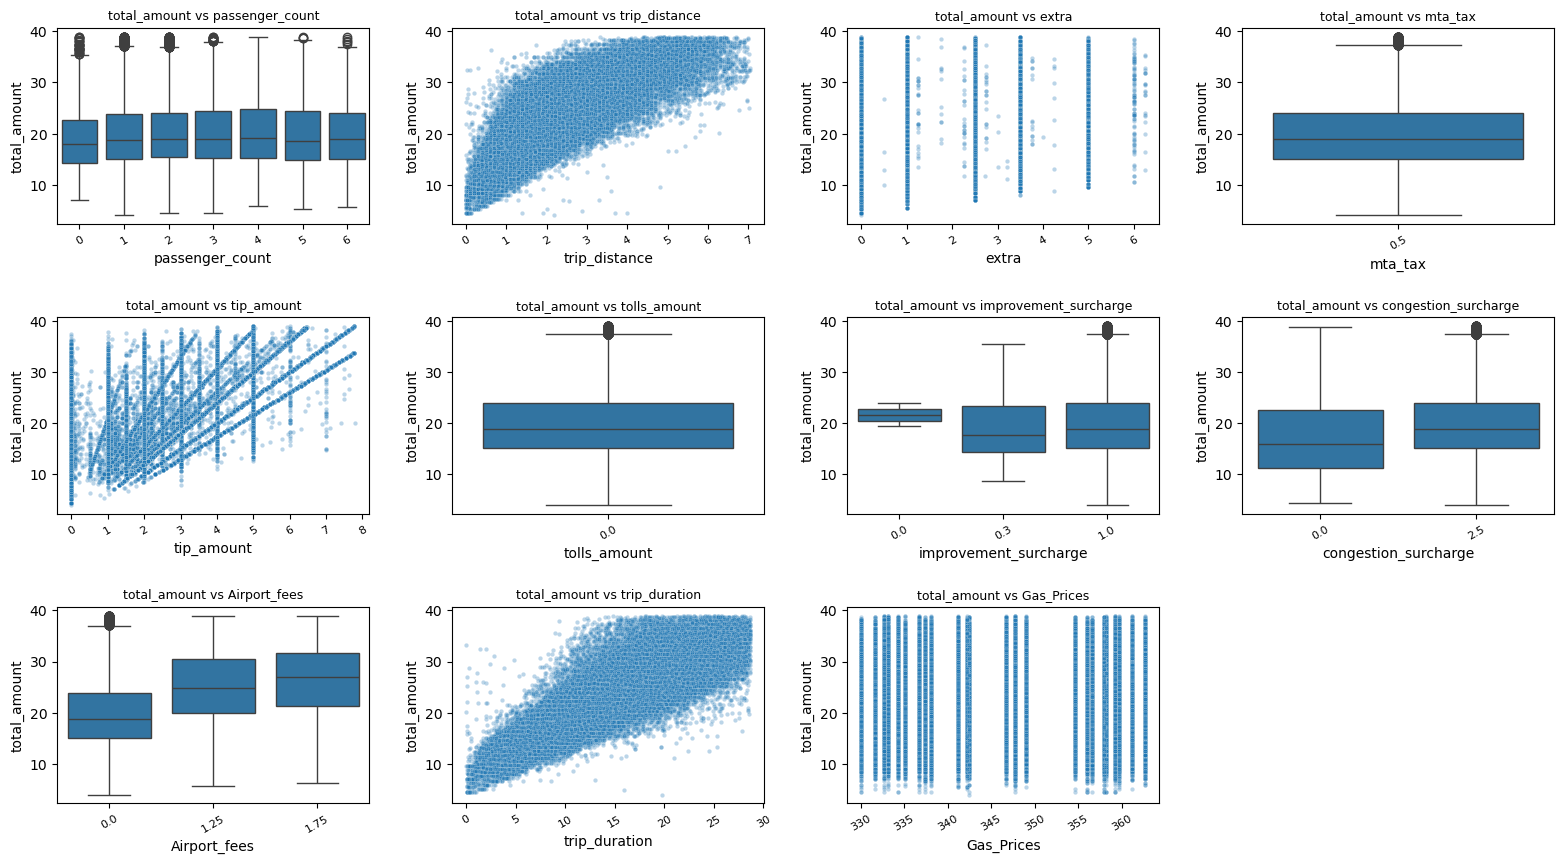

In [40]:
n = len(features_num)
ncols = 4
nrows = int(np.ceil(n / ncols))

# Create subplot
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.flatten() # Flatten to easily iterate 

numeric_target=targets[1]

# Plot each scatter plot
for i, col in enumerate(features_num):
    if df_no_outliers[col].nunique() < 10:
        sns.boxplot(data=df_no_outliers, x=col, y=numeric_target, ax=axes[i])
    else:
        sns.scatterplot(data=df_no_outliers, x=col, y=numeric_target, ax=axes[i], alpha=0.3, s=10)
    
    axes[i].set_title(f"{numeric_target} vs {col}", fontsize=9)
    axes[i].tick_params(axis='x', rotation=30, labelsize=8)

# Hide unused subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(pad=2.0)
plt.savefig("diagramsfornumericalvariables-totalamount.png", dpi=300, bbox_inches="tight")
plt.show()

*Categorical features*

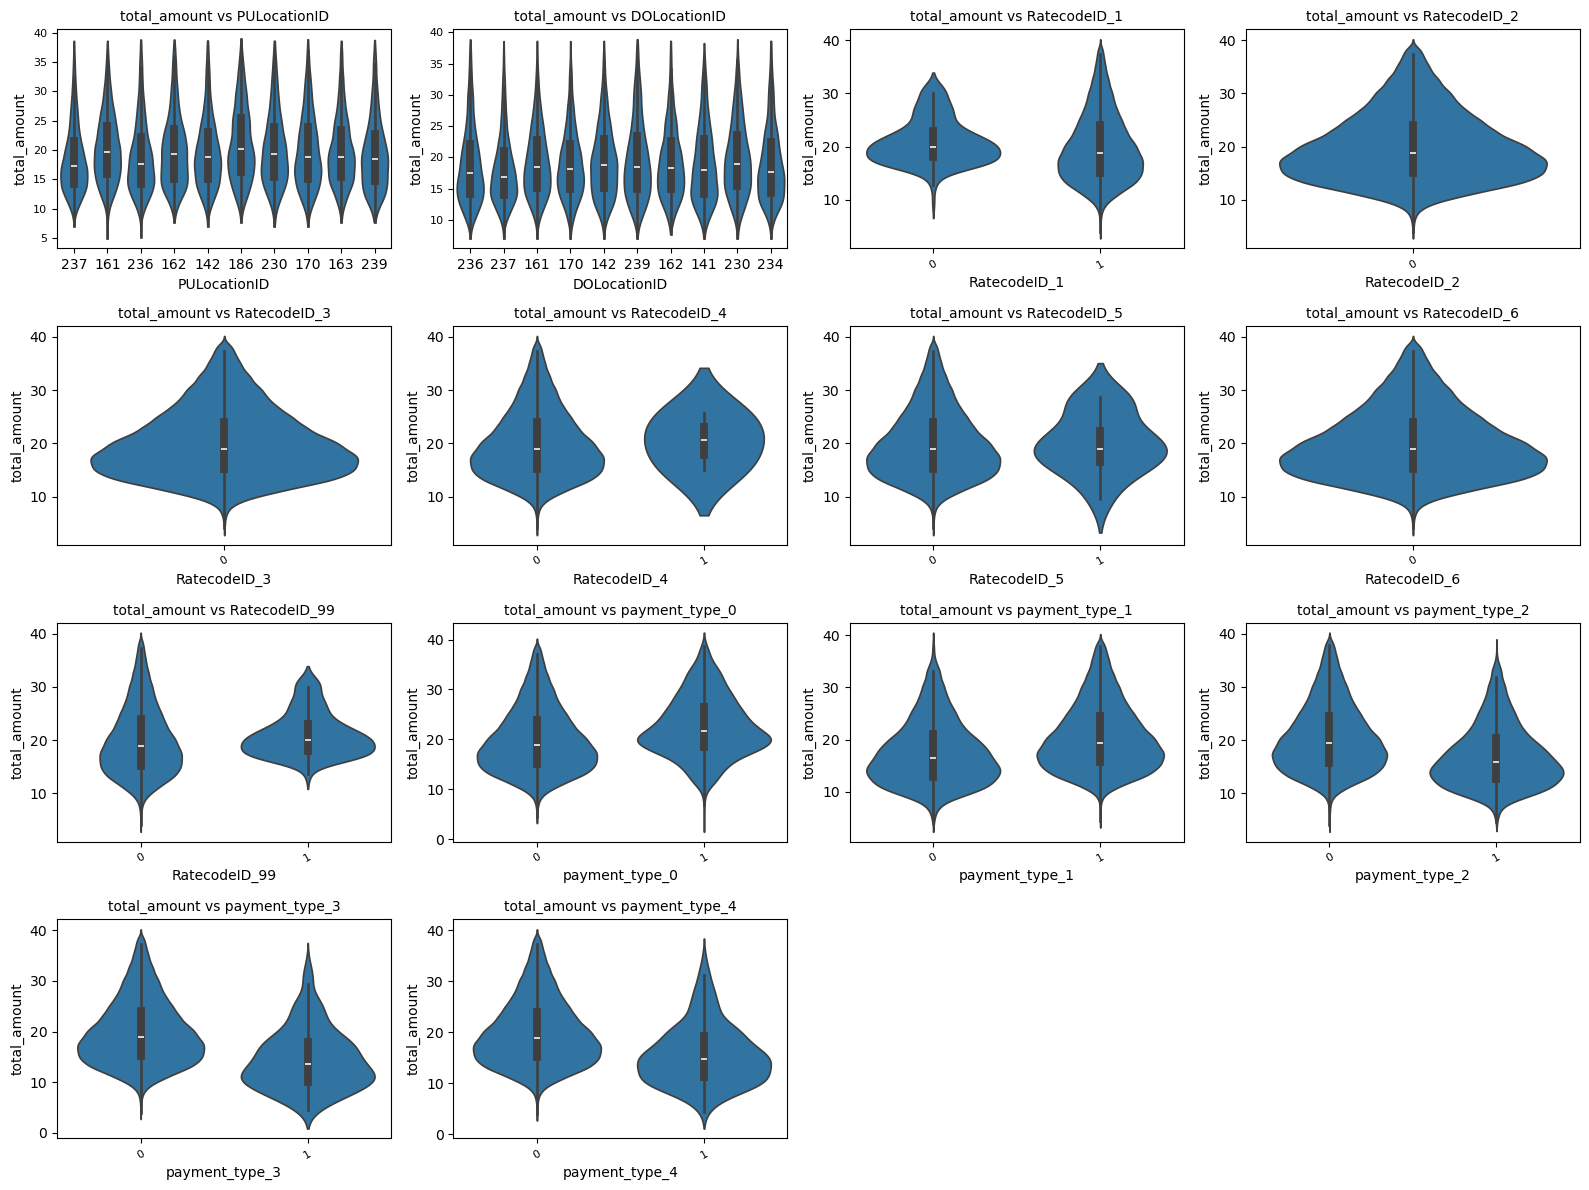

In [41]:
n = len(features_cat)
ncols = 4
nrows = int(np.ceil(n / ncols))

numeric_target=targets[1]

# Create subplot
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3*nrows))
axes = axes.flatten() # Flatten to easily iterate 


# Plot each histogram
for i, col in enumerate(features_cat):
    n_unique = df_no_outliers[col].nunique()

    if n_unique <= 10:  
        # Small number of categories → vertical barplot
        sns.violinplot(data=df_no_outliers, x=col, y=numeric_target,ax=axes[i])
        axes[i].tick_params(axis='x', rotation=30, labelsize=8)

    else:  
        # Select top 10 most frequent categories
        top_k = df_no_outliers[col].value_counts().nlargest(10).index
        
        # Filter dataset to only those categories
        subset = df_no_outliers[df_no_outliers[col].isin(top_k)]
        
        # Violinplot
        sns.violinplot(data=subset,x=col,y=numeric_target,
                       ax=axes[i],order=top_k,
                       scale="width",  # widths comparable
                       cut=0           # no extension beyond observed data
                      )
        axes[i].tick_params(axis='y', labelsize=8)

    axes[i].set_title(f"{numeric_target} vs {col}", fontsize=10)


# hide remaining axes if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.savefig("diagramsforcategoricalvariables-totalamount.png", dpi=300, bbox_inches="tight")
plt.show()

***Key Observations***

1. Passenger Count vs Fare/Total Amount

    * Fare/Total amount is fairly stable across passenger counts → no strong effect.
    * Outliers exist for higher passenger counts.

2. Trip Distance vs Fare/Total Amount

    * Strong positive linear relationship. Longer distances → higher fares.
    * This confirms trip_distance is one of the strongest predictors.

3. Extra vs Fare/Total Amount

    * Only a few discrete values for extra (likely surcharges).
    * Fare increases stepwise when extra charges apply, but overall variation is small compared to distance.

4. MTA Tax vs Fare/Total Amount

    * Boxplot shows a consistent small upward shift in fare when MTA tax is applied. Again, effect is minor relative to distance.

5. Tip Amount vs Fare/Total Amount

    * Positive relationship: higher fares usually come with higher tips. But tips have high variability → not a perfectly linear relationship.

6. Tolls Amount vs Fare/Total Amount

    * Presence of tolls increases fares, but distribution is skewed.
    * Not every trip has tolls, but when they do, fares jump noticeably.

7. Improvement Surcharge vs Fare/Total Amount

    * Slightly higher fares when surcharge = 1. But effect is small and binary.

8. Congestion Surcharge vs Fare/Total Amount

    * Higher fares for trips with congestion surcharge (makes sense).
    * Impact is modest compared to trip distance.

9. Airport Fees vs Fare/Total Amount

    * Trips with airport fees clearly have much higher fares on average.
    
10. Trip Duration vs Fare/Total Amount

    * Another strong positive linear relationship (like trip distance). Long trips → high fares.

11. Gas Prices vs Fare/Total Amount

    * No visible relationship → vertical bands (gas price doesn’t vary much).
   
12. Pickup and Dropoff Location IDs (PULocationID, DOLocationID)

    * Distributions of fares look quite similar across locations.
    * Median fares cluster around the same range (~10–15).
    * Some variability exists (a few locations have slightly higher spreads), but location is not a strong driver of fare differences compared to distance/duration.

13. RatecodeID

    * Most rate codes show overlapping distributions with typical fares (10–15).
    * Some codes (like 3, 4, 5, 6, 99) have wider spreads or slightly higher fare ranges, but these categories are rare (low sample sizes).

14. Payment Type

    * Distribution of fares looks similar across payment types.
    * No clear separation between credit, cash, or other methods.
    * This suggests payment type doesn’t drive the fare amount, but it might correlate with tipping behavior (as shown earlier).

<a id="machine"></a>

### 5. Machine Learning Model

**Importing modules for the predictions**

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

**Define model**

In [43]:
models = {
    "Linear Regression": LinearRegression(n_jobs=-1),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42)
}

**Train, evaluate, collect results**

In [44]:
# Preprocess once
X = df_no_outliers[all_features]
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X[features_num])
X_scaled = np.hstack([X_num_scaled, X[features_cat].values])
feature_names = features_num + features_cat

results = {}
feature_importances = {}

for target in targets:
    print(f"\n===== Predicting {target} =====")
    results[target] = {}

    y = df_no_outliers[target]

    # Train/test split (on preprocessed X)
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.2, random_state=42
    )

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        residuals = y_test - y_pred

        # Metrics
        mae = mean_absolute_error(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, y_pred)

        # Std of error distributions
        mae_std = np.std(np.abs(residuals))
        mse_std = np.std(residuals**2)
        rmse_std = np.std(np.sqrt(residuals**2))
        r2_std = np.std(residuals)

        results[target][name] = {
            "MAE": mae, "MAE_STD": mae_std,
            "MSE": mse, "MSE_STD": mse_std,
            "RMSE": rmse, "RMSE_STD": rmse_std,
            "R²": r2, "R²_STD": r2_std
        }

        print(
            f"{name:20} → "
            f"MAE: {mae:.2f} (±{mae_std:.2f}), "
            f"MSE: {mse:.2f} (±{mse_std:.2f}), "
            f"RMSE: {rmse:.2f} (±{rmse_std:.2f}), "
            f"R²: {r2:.3f} (±{r2_std:.2f})"
        )

        if hasattr(model, "feature_importances_"):
            feature_importances[(target, name)] = pd.Series(
                model.feature_importances_, index=feature_names
            ).sort_values(ascending=False)




===== Predicting fare_amount =====
Linear Regression    → MAE: 0.54 (±0.71), MSE: 0.80 (±5.18), RMSE: 0.89 (±0.71), R²: 0.973 (±0.89)
Random Forest        → MAE: 0.41 (±0.65), MSE: 0.60 (±4.67), RMSE: 0.77 (±0.65), R²: 0.980 (±0.77)
HistGradientBoosting → MAE: 0.46 (±0.59), MSE: 0.56 (±3.77), RMSE: 0.75 (±0.59), R²: 0.981 (±0.75)

===== Predicting total_amount =====
Linear Regression    → MAE: 0.86 (±0.87), MSE: 1.49 (±5.68), RMSE: 1.22 (±0.87), R²: 0.964 (±1.22)
Random Forest        → MAE: 0.46 (±0.80), MSE: 0.85 (±4.86), RMSE: 0.92 (±0.80), R²: 0.979 (±0.92)
HistGradientBoosting → MAE: 0.61 (±0.73), MSE: 0.91 (±4.42), RMSE: 0.96 (±0.73), R²: 0.978 (±0.95)


In [45]:
# Summary table
summary_df = pd.DataFrame(results).stack().unstack(0)
print("\n===== Summary Table =====")
display(summary_df.round(3))


===== Summary Table =====


,Linear Regression,Random Forest,HistGradientBoosting
fare_amount,"{'MAE': 0.5370049198454202, 'MAE_STD': 0.71308...","{'MAE': 0.41373074000000004, 'MAE_STD': 0.6517...","{'MAE': 0.4610639850191026, 'MAE_STD': 0.58897..."
total_amount,"{'MAE': 0.8553707638653035, 'MAE_STD': 0.87181...","{'MAE': 0.456372680000004, 'MAE_STD': 0.799765...","{'MAE': 0.6128353508165255, 'MAE_STD': 0.73249..."


<a id="results"></a>

### 6. Results/Findings

**Show results as tables**

In [46]:
# === Build metrics dataframe ===
metrics_df = []
for target, models_dict in results.items():
    for model_name, metrics in models_dict.items():
        row = {"target": target, "model": model_name}
        row.update(metrics)
        metrics_df.append(row)

metrics_df = pd.DataFrame(metrics_df)

# === Aggregate table grouped by model ===
agg_table = (
    metrics_df
    .groupby(["model",'target'])[["MAE", "MAE_STD", "MSE", "MSE_STD", "RMSE", "RMSE_STD", "R²", "R²_STD"]]
    .mean()   # average across targets
)

# Rename columns for clarity
agg_table = agg_table.rename(columns={
    "MAE": "MAE_mean", "MAE_STD": "MAE_std",
    "MSE": "MSE_mean", "MSE_STD": "MSE_std",
    "RMSE": "RMSE_mean", "RMSE_STD": "RMSE_std",
    "R²": "R2_mean", "R²_STD": "R2_std"
})

print("\n===== Aggregate Table (Grouped by Model) =====")
display(agg_table.round(3))



===== Aggregate Table (Grouped by Model) =====


MAE_mean  MAE_std  MSE_mean  MSE_std  \
model                target                                               
HistGradientBoosting fare_amount      0.461    0.589     0.559    3.765   
                     total_amount     0.613    0.732     0.912    4.417   
Linear Regression    fare_amount      0.537    0.713     0.797    5.182   
                     total_amount     0.855    0.872     1.492    5.679   
Random Forest        fare_amount      0.414    0.652     0.596    4.674   
                     total_amount     0.456    0.800     0.848    4.861   

                                   RMSE_mean  RMSE_std  R2_mean  R2_std  
model                target                                              
HistGradientBoosting fare_amount       0.748     0.589    0.981   0.748  
                     total_amount      0.955     0.732    0.978   0.955  
Linear Regression    fare_amount       0.893     0.713    0.973   0.893  
                     total_amount      1.221     0.872    0.964   1.221  
Random Forest        fare_amount       0.772     0.652    0.980   0.772  
                     total_amount      0.921     0.800    0.979   0.921

**Convert results for plotting**

In [47]:
plot_data = []
for target, model_results in results.items():
    for model_name, metrics in model_results.items():
        entry = {"Target": target, "Model": model_name}
        entry.update(metrics)
        plot_data.append(entry)

results_df = pd.DataFrame(plot_data)

**Plot MAE comparison**

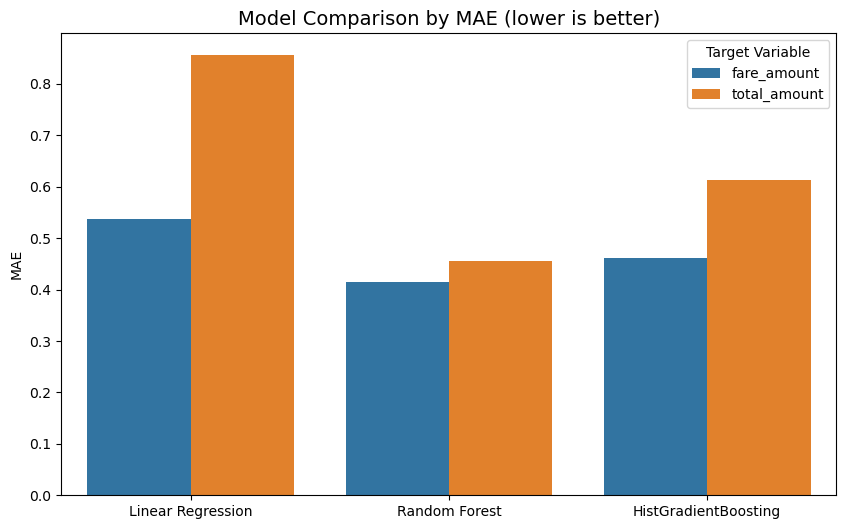

In [54]:
plt.figure(figsize=(10,6))
sns.barplot(data=results_df, x="Model", y="MAE", hue="Target")
plt.title("Model Comparison by MAE (lower is better)", fontsize=14)
plt.ylabel("MAE")
plt.xlabel("")
plt.legend(title="Target Variable")

plt.show()

**Plot MSE comparison**

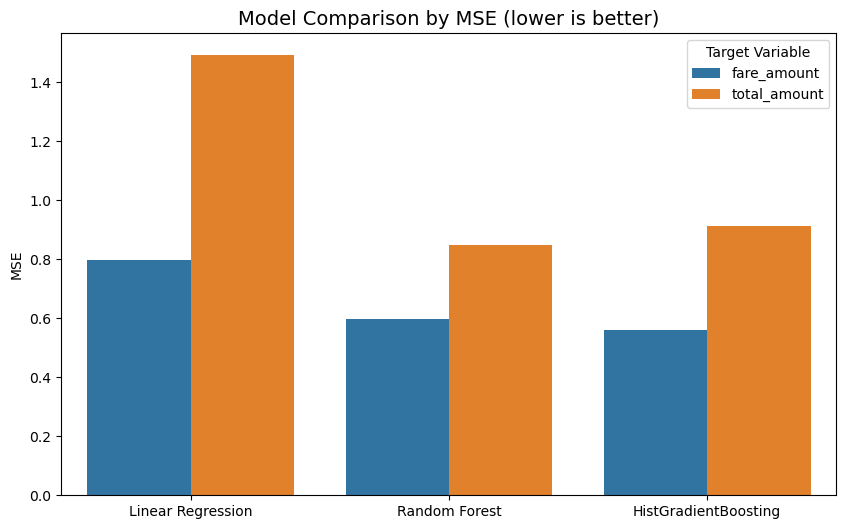

In [55]:
plt.figure(figsize=(10,6))
sns.barplot(data=results_df, x="Model", y="MSE", hue="Target")
plt.title("Model Comparison by MSE (lower is better)", fontsize=14)
plt.ylabel("MSE")
plt.xlabel("")
plt.legend(title="Target Variable")
plt.show()

**Plot RMSE comparison**

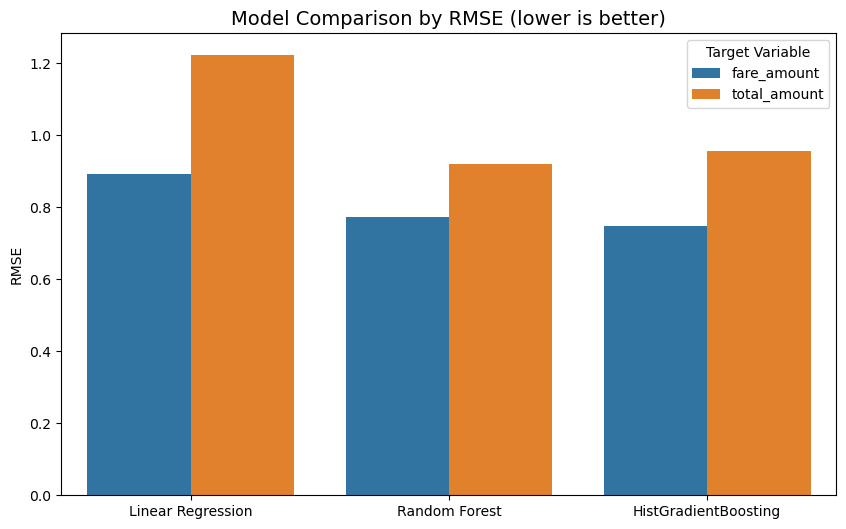

In [50]:
plt.figure(figsize=(10,6))
sns.barplot(data=results_df, x="Model", y="RMSE", hue="Target")
plt.title("Model Comparison by RMSE (lower is better)", fontsize=14)
plt.ylabel("RMSE")
plt.xlabel("")
plt.legend(title="Target Variable")
plt.show()

**Plot R² comparison**

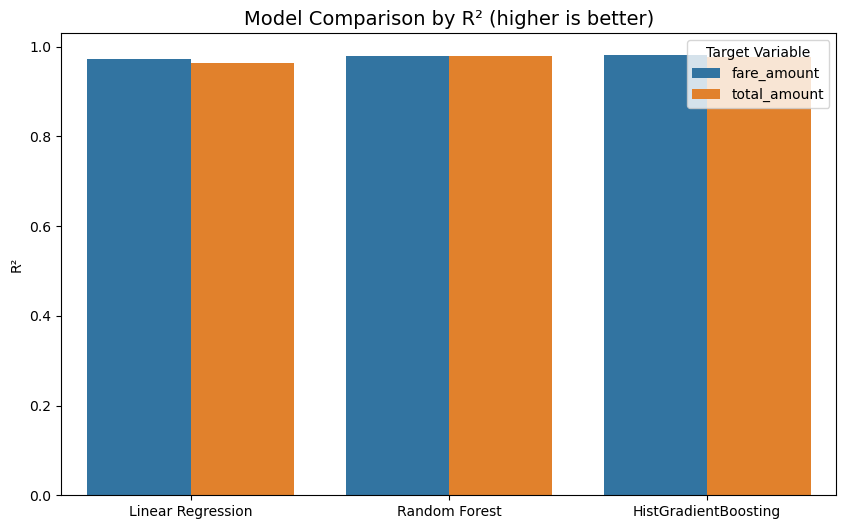

In [51]:
plt.figure(figsize=(10,6))
sns.barplot(data=results_df, x="Model", y="R²", hue="Target")
plt.title("Model Comparison by R² (higher is better)", fontsize=14)
plt.ylabel("R²")
plt.xlabel("")
plt.legend(title="Target Variable")
plt.show()

**Plot feature importance (tree models only)**

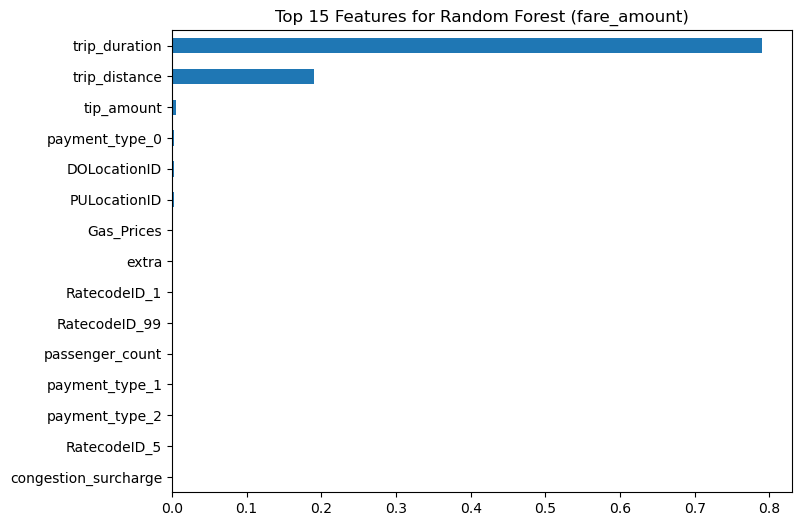

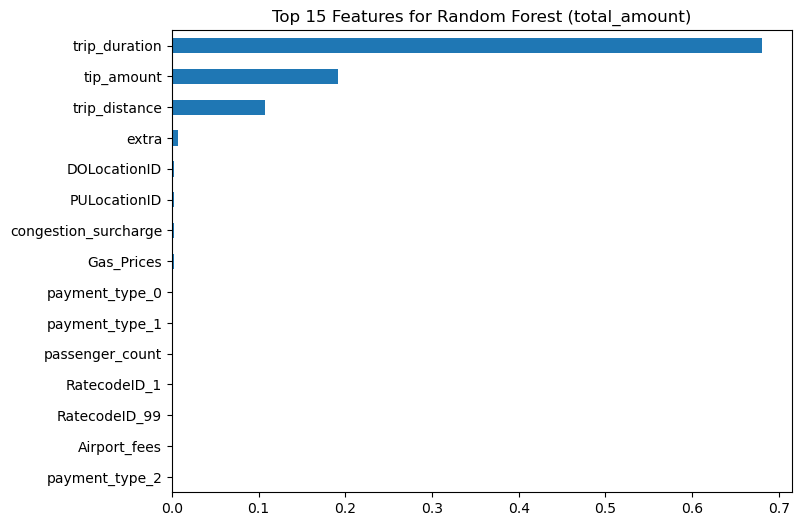

In [52]:
for (target, model_name), fi in feature_importances.items():
    plt.figure(figsize=(8,6))
    fi.head(15).plot(kind="barh")
    plt.title(f"Top 15 Features for {model_name} ({target})")
    plt.gca().invert_yaxis()
    plt.show()

<a id="conclusion"></a>

### 7. Conclusion and Recommendations

This is the final section.